In [9]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import dendrogram, linkage

In [10]:
# Load Iris dataset
iris = load_iris()

# Create DataFrame
df = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

print("First 5 rows:")
print(df.head())

print("\nDataset Shape:", df.shape)

First 5 rows:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2

Dataset Shape: (150, 4)


In [11]:
# Standardize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df)

print("Data preprocessing completed.")

Data preprocessing completed.


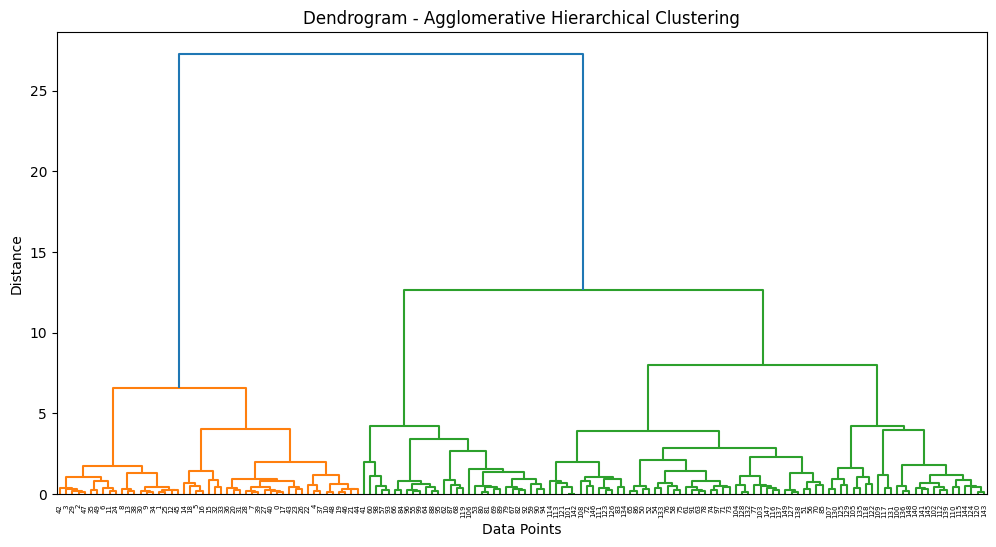

In [12]:
# Create linkage matrix
linked = linkage(X_scaled, method="ward")

# Plot dendrogram
plt.figure(figsize=(12, 6))

dendrogram(linked)

plt.title("Dendrogram - Agglomerative Hierarchical Clustering")
plt.xlabel("Data Points")
plt.ylabel("Distance")
plt.show()

In [13]:
# Create clustering model
model = AgglomerativeClustering(
    n_clusters=3,
    linkage="ward"
)

# Predict cluster labels
df["Cluster"] = model.fit_predict(X_scaled)

print(df.head())
print("\nCluster Distribution:")
print(df["Cluster"].value_counts().sort_index())

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

   Cluster  
0        1  
1        1  
2        1  
3        1  
4        1  

Cluster Distribution:
Cluster
0    71
1    49
2    30
Name: count, dtype: int64


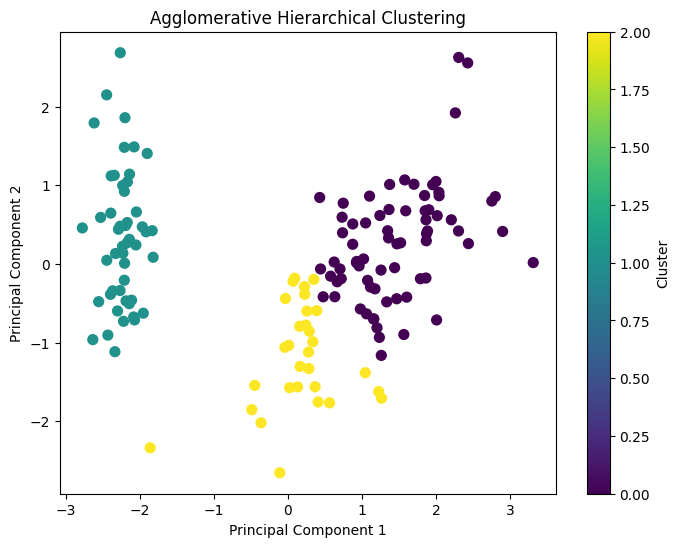

In [14]:
# Reduce 4 features to 2 dimensions for visualization
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(8, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=df["Cluster"],
    cmap="viridis",
    s=50
)

plt.title("Agglomerative Hierarchical Clustering")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.colorbar(label="Cluster")
plt.show()

In [15]:
print("Agglomerative Hierarchical Clustering completed successfully!")

print("\nFinal Dataset:")
print(df.head(10))

print("\nNumber of clusters:", df["Cluster"].nunique())

Agglomerative Hierarchical Clustering completed successfully!

Final Dataset:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   
5                5.4               3.9                1.7               0.4   
6                4.6               3.4                1.4               0.3   
7                5.0               3.4                1.5               0.2   
8                4.4               2.9                1.4               0.2   
9                4.9               3.1                1.5               0.1   

   Cluster  
0        1  
1        1  
2        1  
